# Stuck diodes and streaks

### What you will learn

1. what a stuck diode looks like in an image and in a file's per-diode counts;
2. how a single stuck column changes a particle's size, using the package's own sizing;
3. what the UIOOPS-lineage stuck-diode rule catches, and the kind of episode it misses;
4. what SODA-2's `fixstuckbits` does, run on a synthetic buffer;
5. what is known about how often this happens;
6. how to look for it in your own data, and what is on by default.

### What data this uses

None from disk. Every image and count is *synthetic*. Pixel size is assumed to be 10 µm.

**Before this:** [05_triage_and_gallery](../1_getting_started/05_triage_and_gallery.ipynb) (Looking at particles: a contact sheet, a gallery, and the triage page), [12_particle_gallery](12_particle_gallery.ipynb) (What is not a particle: a gallery of optical array probe artifacts). **Related:** [01_find_stuck_diodes](01_find_stuck_diodes.ipynb). **Needs:** `pip install "arrayprobe[extra,zarr]"` (matplotlib, xarray).

This notebook reads files from the arrayprobe source repository, so run it from a clone of that repository; `pip install arrayprobe` alone does not include them.

The next cell checks that the notebook runs from the repository root, where the paths below start.

In [1]:
# Launch guard: the cells below reach scripts/ and tests/data/ relative to the repository root.
from pathlib import Path

if not (Path("scripts").is_dir() and Path("tests/data").is_dir()):
    raise RuntimeError(
        f"This notebook must run with the repository root as its working directory, not {Path.cwd()}. "
        "Jupyter starts a kernel in the notebook's own folder (examples/5_data_quality/), so run "
        "`%cd ../..` in a new cell, then run this cell again. "
        "Headless, from the repository root: python scripts/execute_example_notebooks.py --check <name>"
    )

import sys

if "examples" not in sys.path:  # shared helper modules (_style.py) sit in examples/
    sys.path.insert(0, "examples")

## 1. What it looks like

An image is a boolean array, `True` where a diode was in shadow; time (slices) runs along the horizontal axis and
the diodes along the vertical axis, diode 1 at the top. A *stuck* diode reads "shadowed" on every slice, so it draws a straight horizontal line along the
time axis, through or beside whatever particle is there. Left: a clean drop. Middle: the same drop
with diode 40 stuck dark. Right: the same image after the UIOOPS-lineage re-illumination
(`c(:,shadow_diode)='1'`, set to lit) of that diode.

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

N = 48
ii, jj = np.mgrid[0:N, 0:N]
drop = (ii - 24) ** 2 + (jj - 20) ** 2 <= 6 ** 2
STUCK = 40                                        # 0-based diode column
streak = drop.copy()
streak[:, STUCK] = True
PX_UM = 10.0

import _style                  # house style: _style.py sits beside this notebook
_style.apply()

def show(ax, img, title, red=None, circle_um=None):
    key = not getattr(ax.figure, "_keyed", False)       # direction key on the first panel of each figure
    ax.figure._keyed = True
    _style.pixels(ax, img, red=red, circle_um=circle_um, um_per_px=PX_UM, title=title, time_x=True, key=key, bar_top=True)

## 2. Why it matters: the size changes

The engine sizes a particle by the smallest circle enclosing every shadowed pixel
(`arrayprobe_uiops.min_circle.cgal_min_r_v35`, called by `measure_record`, `measure.py:264`).
A full-length line is shadowed pixels the drop does not own, so the circle must reach the line.
The cell below sizes the drop clean, with the streak, and after `reilluminate`
(`src/arrayprobe_uiops/diode_mask.py:204`). `reilluminate` takes a `(slices, diodes)` uint8 ASCII
image in which `'1'` (49) is lit and `'0'` (48) is shadowed, and a list of 1-based diode numbers.

clean drop           size  13.0 px =  130 um, reject '0'
with stuck diode     size  48.2 px =  482 um, reject 'p'
after reilluminate   size  13.0 px =  130 um, reject '0'
re-illuminated image equals the clean drop: True


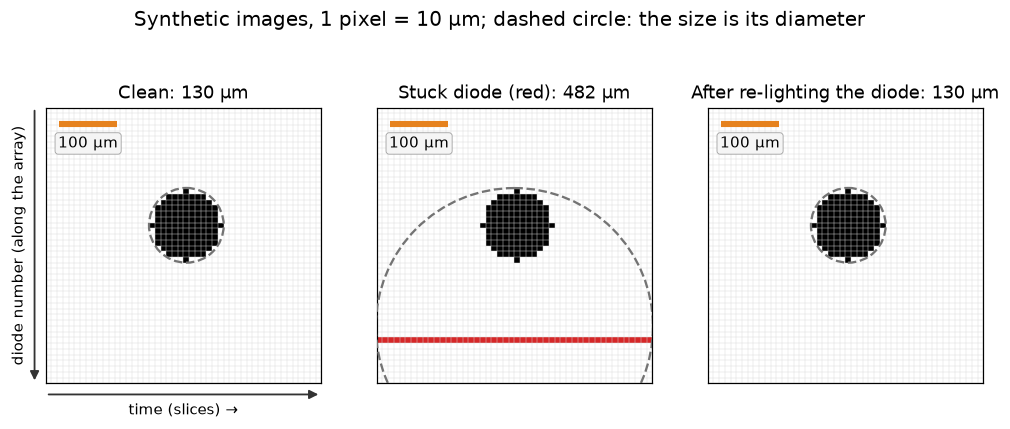

In [3]:
from arrayprobe_uiops.diode_mask import reilluminate
from arrayprobe_uiops.min_circle import cgal_min_r_v35
from arrayprobe_uiops.reject import calculate_reject_unified, is_it_hollow
from arrayprobe_uiops.reject_core import RejectConfig

def to_codes(img):
    return np.where(img, 48, 49).astype(np.uint8)

def size_px(img):
    return cgal_min_r_v35(to_codes(img).astype(np.int64), 1.0)[0]

def reject(img):
    hollow = int(is_it_hollow(img, N)[0])
    return calculate_reject_unified(to_codes(img).astype(np.int64), "S", hollow,
                                    RejectConfig()).reject_status

fixed = reilluminate(to_codes(streak), [STUCK + 1]) == 48     # back to a boolean image
for name, im in [("clean drop", drop), ("with stuck diode", streak), ("after reilluminate", fixed)]:
    print(f"{name:20s} size {size_px(im):5.1f} px = {size_px(im) * PX_UM:4.0f} um, reject {reject(im)!r}")
print("re-illuminated image equals the clean drop:", bool((fixed == drop).all()))

fig, axs = plt.subplots(1, 3, figsize=(11, 4.4))
show(axs[0], drop, f"Clean: {size_px(drop) * PX_UM:.0f} µm", circle_um=size_px(drop) * PX_UM)
show(axs[1], streak, f"Stuck diode (red): {size_px(streak) * PX_UM:.0f} µm",
     red=streak & ~drop, circle_um=size_px(streak) * PX_UM)
show(axs[2], fixed, f"After re-lighting the diode: {size_px(fixed) * PX_UM:.0f} µm",
     circle_um=size_px(fixed) * PX_UM)
fig.suptitle("Synthetic images, 1 pixel = 10 µm; dashed circle: the size is its diameter")
fig.savefig("examples/figures/stuck_streak.png", dpi=110, bbox_inches="tight")
plt.show()

The reject code printed for the stuck-diode image is `'p'`. In the engine's reject routine
(`calculate_reject_unified`, `src/arrayprobe_uiops/reject.py:399-400`) `'p'` means the
shadowed pixels fill less than `shadowed_area` percent of the particle's bounding rectangle
(`RejectConfig.shadowed_area`, default 25, `reject_core.py:57-59`; the same test sits at
the corresponding line of the v3.1.4 port, which this package does not include). A full-length line stretches the
bounding rectangle across the whole array, so a compact drop fills too little of it.

Water content scales as $D^3$, so a size error grows cubed:
$M_{\rm with}/M_{\rm without} \approx (D_{\rm with}/D_{\rm without})^{3}$ (the same arithmetic as the
stray-pixel notebook).

**Why it happens.** A fouled or failed array element. The UIOOPS fork's mask (`find_shadow_diodes.m`)
flags the diode but records no physical mechanism, so none is expanded on here.

## 3. What the UIOOPS-lineage rule catches, and what it misses

`find_shadow_diodes.m` counts, over a whole file, how many slices each diode was *lit*
(`bin_stats`) and calls a diode stuck when its count falls below 0.80 of the file maximum
(or of the mean, if some diodes are over 1.2 times the mean; `diode_mask.py:36-40`, `stuck_diodes`
at `:126`). The rule sees only the file-wide total. A diode stuck for only part of the file keeps
a count above 0.80 of the maximum and is not flagged. The cell makes a 4,000-slice file with diode 20 stuck dark for a
growing fraction of the slices, and runs the package's own rule.

stuck for 100% of the file: lit count    0 vs file max 3841 (threshold 3073) -> flagged: True
stuck for  75% of the file: lit count  947 vs file max 3826 (threshold 3061) -> flagged: True
stuck for  50% of the file: lit count 1914 vs file max 3821 (threshold 3057) -> flagged: True
stuck for  30% of the file: lit count 2646 vs file max 3833 (threshold 3066) -> flagged: True
stuck for  25% of the file: lit count 2855 vs file max 3828 (threshold 3062) -> flagged: True
stuck for  20% of the file: lit count 3044 vs file max 3830 (threshold 3064) -> flagged: True
stuck for  15% of the file: lit count 3248 vs file max 3823 (threshold 3058) -> flagged: False
stuck for  10% of the file: lit count 3426 vs file max 3833 (threshold 3066) -> flagged: False
stuck for   5% of the file: lit count 3606 vs file max 3825 (threshold 3060) -> flagged: False


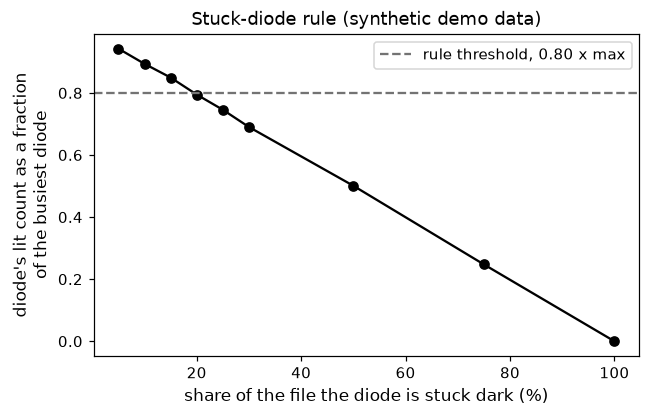

In [4]:
from arrayprobe_uiops.diode_mask import stuck_diodes

rng = np.random.default_rng(1)
nslices, ndiodes, DIODE = 4000, 48, 20
fractions = [1.0, 0.75, 0.5, 0.3, 0.25, 0.2, 0.15, 0.1, 0.05]
caught, counts = [], {}
for f in fractions:
    lit = rng.random((nslices, ndiodes)) > 0.05          # 5 % of slices shadowed at random
    lit[: int(f * nslices), DIODE] = False                # stuck dark for the first fraction f
    bin_stats = lit.sum(axis=0)
    rule = stuck_diodes(bin_stats)
    caught.append(DIODE + 1 in rule.shadow_diode)         # rule returns 1-based numbers
    counts[f] = bin_stats
    print(f"stuck for {f:4.0%} of the file: lit count {bin_stats[DIODE]:4d} vs file max {bin_stats.max()} "
          f"(threshold {rule.threshold:.0f}) -> flagged: {caught[-1]}")

fig, ax = plt.subplots(figsize=(6.4, 3.8))
import _style
_style.apply()
ax.plot([100 * f for f in fractions], [counts[f][DIODE] / counts[f].max() for f in fractions],
        "o-", color="k")
ax.axhline(0.80, color=_style.RULE, ls="--", label="rule threshold, 0.80 x max")
ax.set_xlabel("share of the file the diode is stuck dark (%)")
ax.set_ylabel("diode's lit count as a fraction\nof the busiest diode")
ax.set_title("Stuck-diode rule (synthetic demo data)")
ax.legend(fontsize=10)
fig.savefig("examples/figures/stuck_rule.png", dpi=110, bbox_inches="tight")
plt.show()

*Figure 2. Lit count of the stuck diode as a fraction of the busiest diode, against the share of the synthetic file it is stuck dark; the dashed line is the rule's 0.80 threshold.*

Read the printed flags for where the rule starts to fire in this synthetic file. The crossing is
where the lit count passes $0.80\,\max$, so it depends on the background shadowing: it is a
property of this example, not a campaign figure. A stuck episode below the crossing is not masked
by this rule, and its streaks reach the sizing exactly as in section 2.

## 4. SODA-2's `fixstuckbits`

SODA-2 handles stuck bits at the buffer level. `arrayprobe_soda2.fixstuckbits.fixstuckbits`
(`fixstuckbits.py:86`, port of `fixstuckbits.pro`) totals each diode over the buffer, takes a
width-7 median across diodes, and treats a diode whose total differs from that median by more than
$10\sqrt{\operatorname{median}(h)}$ as stuck (module docstring; code at `:120-130`). It zeroes the
column and copies the *left* neighbour into it. The image has the diode axis first. Below it is run
on a synthetic buffer of 64 diodes and 2,000 slices: with one stuck diode, with two adjacent ones,
and with none.

In [5]:
from arrayprobe_soda2.fixstuckbits import fixstuckbits

rng = np.random.default_rng(2)
base = (rng.random((64, 2000)) < 0.03).astype(np.int32)   # diode axis first; 1 = shadowed here

def run(label, img):
    out = fixstuckbits(img)
    changed = np.flatnonzero((out != img).any(axis=1))
    print(f"{label:36s} diodes changed (0-based): {changed.tolist()}")
    return out

one = base.copy(); one[30, :] = 1
two = base.copy(); two[30:32, :] = 1
o1 = run("one stuck diode (30)", one)
o2 = run("two adjacent stuck diodes (30, 31)", two)
o0 = run("no stuck diode", base)
print("one stuck diode: column 30 now equals its left neighbour:", bool((o1[30] == one[29]).all()))
print("two adjacent: column 31 is all zero:", bool((o2[31] == 0).all()))

one stuck diode (30)                 diodes changed (0-based): [30]
two adjacent stuck diodes (30, 31)   diodes changed (0-based): [30, 31]
no stuck diode                       diodes changed (0-based): [56]
one stuck diode: column 30 now equals its left neighbour: True
two adjacent: column 31 is all zero: True


What the run shows for this port: a single stuck column is replaced by its neighbour; of two
adjacent stuck columns the second is left blank (the port's docstring says so,
`fixstuckbits.py:40-44`); and on a buffer with no stuck diode the routine still rewrites diode
$n-8$, a column the data did not flag. That last behaviour is the port reproducing a defect in the
IDL (the port's docstring says it was measured under GDL). The repository's
guard for it is `no_stuck_diode_fix` (section 7). This routine acts on a SODA-2 buffer, so its
numbers are not directly comparable with the UIOOPS images above. Which polarity of stuck bit
(always shadowed, or always lit) it is meant for is not established by the cells run here.

## 5. How often

- **Stuck diode**: on one particle in one file of a field campaign, diode 124 was shadowed in
  99.68 % of 929 slices; in two files, two diodes read 42.5 %
  and 66.5 % of the file mean. There is no campaign-wide
  rate: not measured yet.
- **Streak / stuck-bit column** (the SODA-2 `streak` routine): not measured yet.

## 6. Check your own data

Per-diode lit counts are all the UIOOPS rule needs. If you can get a file's slices as a
`(slices, diodes)` boolean array `lit`, the cell below prints the diodes the rule flags and the
lit fraction of the dimmest ones, so you can see a diode just above the threshold. It runs here on
a synthetic stand-in with a 20 % episode.

In [6]:
lit = rng.random((4000, 48)) > 0.05                         # replace with your own array
lit[:800, 20] = False                                       # a 20 % episode, as in section 3
rule = stuck_diodes(lit.sum(axis=0))
print("flagged (1-based):", rule.shadow_diode.astype(int).tolist())
print("lowest five lit fractions:", np.sort(lit.mean(axis=0))[:5].round(3))

flagged (1-based): [21]
lowest five lit fractions: [0.764 0.944 0.944 0.946 0.946]


## Data summary
The stuck-fraction scan of section 3 as a labelled dataset, with units.

In [7]:
import xarray as xr
import pandas as pd

ds = xr.Dataset(
    {"lit_over_max": ("stuck_share", [counts[f][DIODE] / counts[f].max() for f in fractions], {"units": "1"}),
     "flagged": ("stuck_share", np.array(caught, int), {"units": "1 = flagged by the rule"})},
    coords={"stuck_share": ("stuck_share", [100 * f for f in fractions], {"units": "%"})},
    attrs={"description": "synthetic file, diode 20 stuck dark", "units": "given per variable"})
ds

<xarray.Dataset> Size: 216B
Dimensions:       (stuck_share: 9)
Coordinates:
  * stuck_share   (stuck_share) float64 72B 100.0 75.0 50.0 ... 15.0 10.0 5.0
Data variables:
    lit_over_max  (stuck_share) float64 72B 0.0 0.2475 0.5009 ... 0.8938 0.9427
    flagged       (stuck_share) int64 72B 1 1 1 1 1 1 0 0 0
Attributes:
    description:  synthetic file, diode 20 stuck dark
    units:        given per variable

The size of the drop of section 2 with and without the stuck diode.

In [8]:
pd.DataFrame({"image": ["clean drop", "with stuck diode", "after re-illumination"],
              "size (um)": [size_px(im) * PX_UM for im in (drop, streak, fixed)],
              "reject code": [reject(im) for im in (drop, streak, fixed)]})

,image,size (um),reject code
0,clean drop,130.000000,0
1,with stuck diode,482.413544,p
2,after re-illumination,130.000000,0


A diode that is not flagged but has a lit fraction clearly below its neighbours is the episode case
of section 3. A per-slice check (does one diode go dark for a long run of consecutive slices?)
would find it; the repository has no such function, so this notebook does not run one.

## 7. Defaults

From [the configuration page](../../docs/06-configuration.md#corrections-engine-35-applies-by-default) and the [enhancements page](../../docs/05-enhancements.md).

| | Default | Turn it on / off |
|---|---|---|
| UIOOPS stuck-diode mask | off for every probe; `imgproc_sm_v35(shadow_diode=None)` writes the bytes of a run without it (`run_flight.py:3182-3207`) | `--diode-corrected` applies a mask only to files in `SHADOW_DIODE_OVERRIDES` (two 2016 field-campaign stems, `run_flight.py:3277`), writing `*.diodecorrected.nc`; every other file has no mask |
| SODA-2 `fixstuckbits` | off: option `stuckbits` defaults 0 (`update_op.py:22`) | set `stuckbits=1` in the op; the parallel driver refuses it (`cli.py:2108`) |
| `no_stuck_diode_fix` (guard for the defect in section 4) | on for every SODA-2 probe, inert unless `stuckbits=1` (`registry.py:122-127`) | `--protective off`, or `no_stuck_diode_fix = false` |

In short, a UIOOPS-lineage run has no stuck-diode correction unless you ask for it.

## What to try next

- Change the stuck-fraction list in section 3 to find where the rule starts to flag, for a heavier or lighter background.
- Put the stuck diode through the middle of the drop (diode 20) in section 2 and compare sizes.
- Make the stuck diode two adjacent columns and re-illuminate only one.
- Next notebook: [18_edge_touching.ipynb](18_edge_touching.ipynb) (a particle cut by the array edge).